# Baseline: XGBoost on per-field season features

Input: `data/merged_barc.parquet` from `preprocessing/merge_features.ipynb` (one row per field, date and sensor).
Labels are per field and year, so the time series is first reduced to **one row per field-year**.

1. Build season features per field-year (no labels involved)
2. Join the Grain/Silage labels (44 field-years, 12 Silage)
3. Validate two ways: leave-one-year-out, and grouped by field
4. Compare XGBoost with a one-feature timing rule

With 44 samples the scores are rough estimates. Read them with the fold counts next to them.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Add the repo root to the import path so the notebook works from any location
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocessing" / "loader.py").exists())
sys.path.insert(0, str(ROOT))
from preprocessing.loader import barc_labels

GPKG = ROOT / "04_Evaluation" / "BARC_Corn.2021-2023.gpkg"
SEED = 0

merged = pd.read_parquet(ROOT / "data" / "merged_barc.parquet")
print(merged.shape)

(14689, 38)


## 1. Features per field-year

Sentinel-2 only: its NDVI reads about 0.05 lower than Landsat's, so mixing the two would add a fake step to the curve.

| Feature | Meaning | Hypothesis |
|---|---|---|
| `ndvi_m07` ... `ndvi_m11`, `ndti_*`, `ndmi_*` | monthly medians | shape of the season |
| `peak_ndvi`, `peak_doy` | highest NDVI, June to September | crop vigour and timing |
| `drop_doy` | first day after the peak with NDVI below half the peak | harvest date: Silage earlier |
| `ndvi_before_drop` | last NDVI seen before the drop | Silage is cut while still green |
| `drop_gap_days` | days between those two readings | how uncertain `drop_doy` is (clouds) |
| `max_drop_rate` | steepest NDVI fall per day after the peak | cutting is abrupt, dry-down is gradual |
| `ndti_post`, `ndvi_post` | medians in the 30 days from the drop | Grain leaves more residue (higher NDTI) |

`farm`, area and location are left out on purpose: they could identify BARC's silage fields without saying anything about harvest.

In [2]:
MONTHS = [7, 8, 9, 10, 11]
HALF = 0.5          # the drop is the first reading below HALF * peak NDVI
POST_DAYS = 30


def season_features(g):
    g = g.sort_values("date")
    out = {"n_obs": len(g)}
    month = g["date"].dt.month
    for m in MONTHS:
        sel = g[month == m]
        for col in ("ndvi", "ndti", "ndmi"):
            out[f"{col}_m{m:02d}"] = sel[col].median()

    summer = g[(g["doy"] >= 152) & (g["doy"] <= 273)]      # June 1 to September 30
    if summer.empty:
        return out
    peak = summer.loc[summer["ndvi"].idxmax()]
    out["peak_ndvi"], out["peak_doy"] = peak["ndvi"], peak["doy"]

    after = g[g["doy"] > peak["doy"]]
    if len(after):
        steps = np.diff(np.r_[peak["ndvi"], after["ndvi"].values]) / np.diff(np.r_[peak["doy"], after["doy"].values])
        out["max_drop_rate"] = steps.min()
    low = after[after["ndvi"] < HALF * peak["ndvi"]]
    if len(low):
        drop = low.iloc[0]
        before = g[g["doy"] < drop["doy"]].iloc[-1]
        post = g[(g["doy"] >= drop["doy"]) & (g["doy"] <= drop["doy"] + POST_DAYS)]
        out.update(drop_doy=drop["doy"], ndvi_before_drop=before["ndvi"],
                   drop_gap_days=drop["doy"] - before["doy"],
                   ndti_post=post["ndti"].median(), ndvi_post=post["ndvi"].median())
    return out


s2 = merged[(merged["sensor"] == "S2") & merged["ndvi"].notna()]
feats = pd.DataFrame([{"field_id": fid, "year": year, **season_features(g)}
                      for (fid, year), g in s2.groupby(["field_id", "year"])])
FEATURES = [c for c in feats.columns if c not in ("field_id", "year")]
print(feats.shape, "|", len(FEATURES), "features")
feats.head()

(249, 26) | 24 features


,field_id,year,n_obs,ndvi_m07,ndti_m07,ndmi_m07,ndvi_m08,ndti_m08,ndmi_m08,ndvi_m09,...,ndti_m11,ndmi_m11,peak_ndvi,peak_doy,max_drop_rate,drop_doy,ndvi_before_drop,drop_gap_days,ndti_post,ndvi_post
0,1,2021,58,0.807602,0.323501,0.301833,0.753456,0.310936,0.201003,0.350277,...,0.215813,0.062085,0.860326,193,-0.294176,255.0,0.453227,2.0,0.146493,0.226717
1,1,2022,55,0.530375,0.225581,0.011185,0.757051,0.277479,0.200940,0.712096,...,0.172566,-0.094395,0.827949,235,-0.023860,280.0,0.582453,10.0,0.171127,0.310996
2,1,2023,56,0.822024,0.348960,0.275577,0.832150,0.367392,0.320027,0.606202,...,0.204821,-0.127065,0.866666,228,-0.033882,270.0,0.557860,7.0,0.204394,0.409904
3,4,2021,59,0.752217,0.373554,0.314016,0.371099,0.235748,-0.094063,0.467174,...,0.264934,0.089267,0.840459,203,-0.296343,220.0,0.421541,2.0,0.224990,0.384074
4,4,2022,53,0.804114,0.350105,0.323732,0.634970,0.285970,0.079604,0.546267,...,0.239854,0.033194,0.843604,193,-0.120851,205.0,0.596248,2.0,0.262987,0.592106


## 2. Join labels

Only labelled field-years are kept. Blank labels are not negative examples. `y = 1` means Silage.

In [3]:
labels = barc_labels(GPKG)
data = labels.merge(feats, on=["field_id", "year"], how="left")
data["y"] = (data["harvest_type"] == "Silage").astype(int)
X, y = data[FEATURES], data["y"]

print("field-years:", len(data), "| missing all features:", int(X.isna().all(axis=1).sum()))
pd.crosstab(data["year"], data["harvest_type"], margins=True)

field-years: 44 | missing all features: 0


harvest_type,Grain,Silage,All
year,,,
2021,14,4,18
2022,3,4,7
2023,15,4,19
All,32,12,44


In [4]:
# Look before fitting: the main timing and residue features by class
show = ["drop_doy", "ndvi_before_drop", "max_drop_rate", "ndti_post", "ndvi_m09", "ndvi_m10", "peak_doy"]
data.groupby("harvest_type")[show].agg(["median", "count"]).T.unstack().round(3)

harvest_type        Grain         Silage      
                   median count   median count
drop_doy          270.000  32.0  256.500  12.0
ndvi_before_drop    0.544  32.0    0.820  12.0
max_drop_rate      -0.039  32.0   -0.055  12.0
ndti_post           0.192  32.0    0.116  12.0
ndvi_m09            0.575  32.0    0.290  12.0
ndvi_m10            0.339  32.0    0.266  12.0
peak_doy          203.000  32.0  200.000  12.0

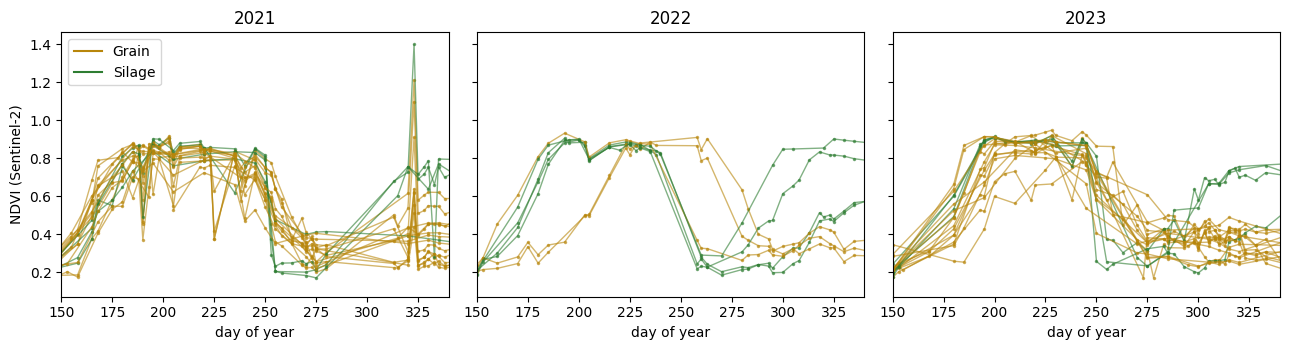

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
colors = {"Grain": "#b8860b", "Silage": "#2e7d32"}
curves = s2.merge(labels, on=["field_id", "year"])
for ax, (year, g) in zip(axes, curves.groupby("year")):
    for (fid, kind), f in g.groupby(["field_id", "harvest_type"]):
        ax.plot(f["doy"], f["ndvi"], color=colors[kind], alpha=0.6, lw=1, marker=".", ms=3)
    ax.set_title(str(year)); ax.set_xlabel("day of year"); ax.set_xlim(150, 340)
axes[0].set_ylabel("NDVI (Sentinel-2)")
axes[0].legend(handles=[plt.Line2D([], [], color=c, label=k) for k, c in colors.items()])
plt.tight_layout()

## 3. Validation design

The same field appears in several years, and neighbouring fields share weather. A random split would leak.

- **Leave one year out**: train on two years, test on the third. Answers "does it carry over to a new season?"
- **Grouped by field** (5 folds, stratified): no field is in both train and test.

Every prediction below is out-of-fold.

In [6]:
def make_xgb(y_train):
    pos = max(int(y_train.sum()), 1)
    return XGBClassifier(
        n_estimators=200, max_depth=2, learning_rate=0.05,      # small trees: 44 samples
        subsample=0.8, colsample_bytree=0.8, min_child_weight=1, reg_lambda=1.0,
        scale_pos_weight=(len(y_train) - pos) / pos,             # Silage is the minority
        eval_metric="logloss", random_state=SEED, n_jobs=4)


def make_rule(y_train):
    # One split on the drop date. Rows with no detected drop go to the side the tree learns.
    return DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=SEED)


def oof_predict(make_model, X, y, splits):
    proba = pd.Series(np.nan, index=X.index)
    for train, test in splits:
        model = make_model(y.iloc[train]).fit(X.iloc[train], y.iloc[train])
        proba.iloc[test] = model.predict_proba(X.iloc[test])[:, 1]
    return proba


def report(name, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    print(f"=== {name} ===")
    print(classification_report(y, pred, target_names=["Grain", "Silage"], digits=2, zero_division=0))
    print(pd.DataFrame(confusion_matrix(y, pred), index=["true Grain", "true Silage"],
                       columns=["pred Grain", "pred Silage"]), "\n")
    return pred


splits = {
    "leave one year out": list(LeaveOneGroupOut().split(X, y, groups=data["year"])),
    "grouped by field": list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
                             .split(X, y, groups=data["field_id"])),
}
for name, sp in splits.items():
    print(name, "| test sizes:", [len(te) for _, te in sp], "| Silage in test:", [int(y.iloc[te].sum()) for _, te in sp])

leave one year out | test sizes: [18, 7, 19] | Silage in test: [4, 4, 4]
grouped by field | test sizes: [9, 10, 8, 8, 9] | Silage in test: [2, 3, 2, 2, 3]


## 4. Results

In [7]:
RULE_FEATURES = ["drop_doy"]
preds = {}
for split_name, sp in splits.items():
    preds[("rule: drop_doy", split_name)] = report(f"Rule on drop_doy | {split_name}",
                                                   oof_predict(make_rule, X[RULE_FEATURES], y, sp))
    proba = oof_predict(make_xgb, X, y, sp)
    data[f"p_silage_{split_name.replace(' ', '_')}"] = proba
    preds[("xgboost", split_name)] = report(f"XGBoost | {split_name}", proba)

=== Rule on drop_doy | leave one year out ===
              precision    recall  f1-score   support

       Grain       0.80      0.75      0.77        32
      Silage       0.43      0.50      0.46        12

    accuracy                           0.68        44
   macro avg       0.61      0.62      0.62        44
weighted avg       0.70      0.68      0.69        44

             pred Grain  pred Silage
true Grain           24            8
true Silage           6            6 



=== XGBoost | leave one year out ===
              precision    recall  f1-score   support

       Grain       0.93      0.88      0.90        32
      Silage       0.71      0.83      0.77        12

    accuracy                           0.86        44
   macro avg       0.82      0.85      0.84        44
weighted avg       0.87      0.86      0.87        44

             pred Grain  pred Silage
true Grain           28            4
true Silage           2           10 

=== Rule on drop_doy | grouped by field ===
              precision    recall  f1-score   support

       Grain       0.92      0.72      0.81        32
      Silage       0.53      0.83      0.65        12

    accuracy                           0.75        44
   macro avg       0.72      0.78      0.73        44
weighted avg       0.81      0.75      0.76        44

             pred Grain  pred Silage
true Grain           23            9
true Silage           2           10 



=== XGBoost | grouped by field ===
              precision    recall  f1-score   support

       Grain       0.91      0.97      0.94        32
      Silage       0.90      0.75      0.82        12

    accuracy                           0.91        44
   macro avg       0.91      0.86      0.88        44
weighted avg       0.91      0.91      0.91        44

             pred Grain  pred Silage
true Grain           31            1
true Silage           3            9 



In [8]:
# One table: precision and recall for both classes
rows = []
for (model, split_name), pred in preds.items():
    rep = classification_report(y, pred, target_names=["Grain", "Silage"], output_dict=True, zero_division=0)
    rows.append({"model": model, "split": split_name,
                 "Grain precision": rep["Grain"]["precision"], "Grain recall": rep["Grain"]["recall"],
                 "Silage precision": rep["Silage"]["precision"], "Silage recall": rep["Silage"]["recall"],
                 "macro F1": rep["macro avg"]["f1-score"]})
summary = pd.DataFrame(rows).set_index(["split", "model"]).sort_index().round(2)
summary

Grain precision  Grain recall  \
split              model                                           
grouped by field   rule: drop_doy             0.92          0.72   
                   xgboost                    0.91          0.97   
leave one year out rule: drop_doy             0.80          0.75   
                   xgboost                    0.93          0.88   

                                   Silage precision  Silage recall  macro F1  
split              model                                                      
grouped by field   rule: drop_doy              0.53           0.83      0.73  
                   xgboost                     0.90           0.75      0.88  
leave one year out rule: drop_doy              0.43           0.50      0.62  
                   xgboost                     0.71           0.83      0.84

In [9]:
# By year (XGBoost, leave one year out): the number of fields and how many were right
by_year = data.assign(pred=preds[("xgboost", "leave one year out")])
by_year["correct"] = by_year["pred"] == by_year["y"]
by_year.groupby(["year", "harvest_type"])["correct"].agg(n="size", correct="sum")

n  correct
year harvest_type             
2021 Grain         14       12
     Silage         4        3
2022 Grain          3        3
     Silage         4        4
2023 Grain         15       13
     Silage         4        3

## 5. What the model uses

Fitted on all 44 field-years, for inspection only. Not used for any score above.

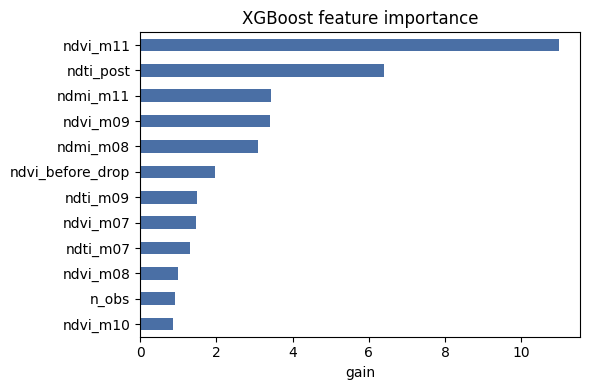

In [10]:
full = make_xgb(y).fit(X, y)
gain = pd.Series(full.get_booster().get_score(importance_type="gain")).sort_values()
gain.tail(12).plot.barh(figsize=(6, 4), color="#4a6fa5")
plt.xlabel("gain"); plt.title("XGBoost feature importance"); plt.tight_layout()

In [11]:
# Errors, for a look at the individual curves
miss = by_year[~by_year["correct"]]
miss[["field_id", "year", "harvest_type", "p_silage_leave_one_year_out", "drop_doy", "ndvi_before_drop",
      "drop_gap_days", "ndti_post", "n_obs"]].round(2)

,field_id,year,harvest_type,p_silage_leave_one_year_out,drop_doy,ndvi_before_drop,drop_gap_days,ndti_post,n_obs
0,1,2021,Grain,0.81,255.0,0.45,2.0,0.15,58
1,24,2021,Grain,0.58,258.0,0.46,3.0,0.17,56
9,327,2021,Silage,0.17,270.0,0.48,15.0,0.16,29
30,248,2023,Silage,0.13,255.0,0.81,5.0,0.17,63
37,347,2023,Grain,0.67,270.0,0.54,25.0,0.16,27
43,400,2023,Grain,0.55,250.0,0.67,5.0,0.15,24
